In [22]:
import pandas as pd
import numpy as np
import re
import jieba
import jieba.analyse
from collections import Counter
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei', 'Microsoft YaHei'] 
plt.rcParams['axes.unicode_minus'] = False  

df = pd.read_excel("changan_lizhi.xlsx")
print(f"There are {len(df)} reviews.")
print(f"Column: {list(df.columns)}")

There are 1100 reviews.
Column: ['作者', '时间', '内容', '赞同', '反对', '转发', '标题']


In [23]:
print("处理前缺失值统计:")
print(df.isnull().sum())

if '作者' in df.columns:
    df['作者'] = df['作者'].fillna("匿名")

if '时间' in df.columns:
    df['时间'] = df['时间'].fillna("未知时间")

if '内容' in df.columns:
    df = df.dropna(subset=['内容'])

for col in ['赞同', '反对', '转发']:
    if col in df.columns:
        df[col] = df[col].fillna(0)

print("重复评论（内容完全一样）详情")

dup_mask = df.duplicated(subset=['内容'], keep=False)
duplicate_comments = df[dup_mask].copy()

if len(duplicate_comments) > 0:
    grouped = duplicate_comments.groupby('内容')
    
    for content, group in grouped:
        print(f"\n重复内容：")
        print(f"内容：{content.strip() if content.strip() else '空内容'}")
        print(f"一共重复：{len(group)} 条")
        print(f"涉及作者：{list(group['作者'].unique())}")
        print(f"涉及时间：{list(group['时间'].unique())}")
        print("-" * 70)

    before_count = len(df)
    df = df.drop_duplicates(subset=['内容'], keep='first')
    after_count = len(df)
    
    print(f"\n去重完成，移除了 {before_count - after_count} 条重复评论")

else:
    print("数据中没有重复内容评论")

print("\n数据清洗全部完成")
print(f"最终数据量：{len(df)} 条")

print("\n处理后缺失值统计:")
print(df.isnull().sum())

处理前缺失值统计:
作者    2
时间    1
内容    0
赞同    0
反对    0
转发    0
标题    0
dtype: int64
重复评论（内容完全一样）详情

重复内容：
内容：今年马伯庸的《长安的荔枝》终于被影视化了，剧版才大结局没多久，电影版也在今天上映，由大鹏自导自演，张若昀，白客以及杨幂也参与其中，演员阵容非常强大，大部分选角都符合书中描写。改编原著，观众会对电影的质量更加苛刻，要还原原著的同时又要改编的合理，所以对大鹏来说，是一个不小的挑战。

但看完电影后不得不说，这部电影真的应该得让大鹏来拍，因为从以往得作品来看，大鹏始终聚焦草根群体的生存状态，能把底层人物的处境拍的淋漓尽致。

例如在《热烈》中，街舞少年陈烁面对家庭债务仍坚持梦想，以及新作《长安的荔枝》里的李善德，都展现了当代小人物的生存困境与精神突围。李善德初入职场时意气风发，到最后白发苍苍。这个人物就像现实中的我们，上班996，存不到钱，听老板画大饼，工作被同事，老板，甲方百般刁难，我们却只能忍气吞声，日日想辞职日日勤恳工作。每天都是”班味十足“。

所以李善德这个角色特别能让观众共情，让观众能迅速代入到李善德身上，李善德所经历的事情，他的情绪起伏时刻牵引着观众的视线。

李善德有句台词：“就算失败，我也想知道，自己倒在距离终点多远的地方。”让我特别有力量，尽管在职场遭遇许多不公，仍然会为了这个不可能完成的任务拼尽全力，小人物也有大力量。

虽然大鹏的电影都是聚焦在底层人物身上，但是大鹏的镜头没有刻意的煽情，一味的 “诉苦”，而是通过李善德 这个“这个灵魂生光的人”，让观众在笑声完成了对自身处境的观照与共鸣。

苏谅，阿僮姑娘，林邑奴的出现就是李善德这个灰暗人生里的一道光，照亮了李善德运送荔枝的漫漫长路，苏谅在绝境中拉了李善德一把，林邑奴护送李善德送荔枝倒在了离长安一步之遥的位置，一个个鲜活的角色让人难以忘记，这大概就是大鹏喜剧的温暖力量吧。电影用着轻松愉快的方式展现官僚体系对个体的碾压，荔枝转运链上的劳民伤财成为"盛世吃人"的隐喻，大鹏从最开始追求简单粗暴即时笑果，到现在“幽默包裹悲剧”叙事美学，他完成了网络喜剧人到现实主义导演的蜕变。作品始终保持着对小人物的平视与共情，所以作为演员的他能演出底层人物的心酸以及不服输的精神。总体来说，《长安的荔枝》非常值得观看！


In [24]:
import pandas as pd
import re

pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', None)

def clean_text_improved(text):
    if pd.isna(text):
        return ""
    text = str(text)
    
    text = re.sub(r'http[s]?://(?:[a-zA-Z]|[0-9]|[$-_@.&+])+', '', text)
    
    text = re.sub(r'<[^>]+>', '', text)
    
    text = re.sub(r'[\x00-\x08\x0b\x0c\x0e-\x1f\x7f]', '', text)
    
    text = re.sub(r'\s+', ' ', text)
    
    text = text.strip()
    
    return text

print("正在清洗评论内容...")
df['cleaned_content'] = df['内容'].apply(clean_text_improved)

df['content_length'] = df['内容'].str.len()
df['cleaned_length'] = df['cleaned_content'].str.len()

print(f"清洗完成")
print(f"清洗前平均长度: {df['content_length'].mean():.0f} 字")
print(f"清洗后平均长度: {df['cleaned_length'].mean():.0f} 字")
print(f"内容保留率: {df['cleaned_length'].mean() / df['content_length'].mean() * 100:.1f}%")

正在清洗评论内容...
清洗完成
清洗前平均长度: 933 字
清洗后平均长度: 923 字
内容保留率: 99.0%


In [25]:
MIN_LENGTH = 20 

print("="*60)
print("过滤长评")
print("="*60)

print(f"原始数据: {len(df)} 条")
print(f"过滤条件: 评论长度 >= {MIN_LENGTH} 字")

df_long = df[df['cleaned_length'] >= MIN_LENGTH].copy()

df = df_long

过滤长评
原始数据: 1086 条
过滤条件: 评论长度 >= 20 字


In [26]:
target_keywords = ["古风", "传统文化", "文化自信", "国风", "生灵涂炭"]

for keyword in target_keywords:
    df[f'包含_{keyword}'] = df['cleaned_content'].str.contains(keyword, na=False, regex=False)

df['包含目标关键词'] = (
    df['包含_古风'] | 
    df['包含_传统文化'] | 
    df['包含_文化自信'] |
    df['包含_国风'] |
    df['包含_生灵涂炭']
)

for keyword in target_keywords:
    count = df[f'包含_{keyword}'].sum()
    print(f"包含「{keyword}」的评论: {count} 条 ({count/len(df)*100:.2f}%)")

filtered_df = df[df['包含目标关键词'] == True].copy()

print(f"\n筛选结果: 共 {len(filtered_df)} 条评论")

包含「古风」的评论: 8 条 (0.74%)
包含「传统文化」的评论: 4 条 (0.37%)
包含「文化自信」的评论: 0 条 (0.00%)
包含「国风」的评论: 1 条 (0.09%)
包含「生灵涂炭」的评论: 8 条 (0.74%)

筛选结果: 共 21 条评论


In [27]:
print("包含「古风、传统文化、文化自信、国风」的评论列表")

if len(filtered_df) == 0:
    print("没有找到包含这些关键词的评论")
else:
    for idx, row in filtered_df.iterrows():
        print(f"评论 {idx+1}")
        
        matched_keywords = []
        for keyword in target_keywords:
            if row[f'包含_{keyword}']:
                matched_keywords.append(keyword)
        print(f"匹配的关键词: {', '.join(matched_keywords)}")
        
        print(f"\n评论内容:")
        print(row['cleaned_content'])
        
        if 'keywords' in row and pd.notna(row['keywords']):
            print(f"\n提取的关键词: {row['keywords'][:10]}")
        
        print(f"\n评论长度: {len(row['cleaned_content'])} 字")

包含「古风、传统文化、文化自信、国风」的评论列表
评论 5
匹配的关键词: 古风

评论内容:
每次看完大鹏导演的新电影，总是惊讶于他的进步之大。电影《长安的荔枝》是他的新高度，表达商业，符合当代审美。马伯庸的原著严谨考究、行云流水、余味悠长。“一骑红尘妃子笑，无人知是荔枝来”，讲的就是这个故事。小说也就七万字，篇幅适中，改编成两小时的电影是最合适的体量。骨架既有，填充肌肉和经络还是颇考功夫。创作者遵循小说架构去设计剧本，节奏打点精准，喜剧主要集中在前面，以轻快的笔调写沉重的主题，表面喜乐实则悲凉。 开篇即以“荔枝使”来布局，点出这场“荔枝鲜”背后的权力游戏。随后，快速勾勒出人物形象——上林署九品监事李善德，从意气风发少年郎初入城起笔，继而铺陈长安百态和人到中年的官场浮沉，各阶段像极了职场中的我们——早高峰、喊口号、背锅、加班、被抢功，耗费半生才换来一间陋室，还得面临房贷重压。马上就引出接下来的核心事件——掉入同僚设下的陷阱，接下了“荔枝使”这个烫手山芋，这任务也像极了职场中被强加的不切实际的绩效指标。刘署令对李善德的威逼利诱，找替死鬼、许诺升职都是典型的职场PUA和画饼行为。唯有家庭生活是职场外的温馨港湾，妻女的陪伴使仕途少了一点寒苦，多了一点红袖添香的浪漫温情。 听说岭南荔枝最为美味，圣人为博贵妃一笑，要派人将鲜荔枝从五千里之遥的岭南运到长安。荔枝“一日色变，两日香变，三日味变”，这个任务天然具备强烈戏剧性。看似升迁美差，实则生死茫茫。李善德的个人命运、家庭未来与任务成败直接绑定。而破解之道，唯有依靠算学和实验不断试错，将原本的不可能一步步变成可能。 故事分阶段呈现了他所遭遇的种种挑战，这种任务驱动型叙事，让角色始终处于高压状态，观众仿佛跟他并肩同行。小说中的许多细节有了可视化的还原，特别是双层瓮、移栽法、格眼簿子、转运舆图等，又辅以台词的解释将枯燥的数据转化为直观的视觉，保留了逻辑的严谨性。 因为李善德精于算学，数字贯穿全片，倒计时数字营造出争分夺秒的紧迫感和速度感。李善德的理科生思维，助他一步步破解难题，展现了逻辑思维的力量。从算房贷的数字到荔枝腐变时间，再到转运路径，还有与杨国忠对峙那场戏，是数学的纯粹理性与权力的激烈对撞。数字不仅是情节要素，更成为衡量人性代价的标尺。这些冷冰冰的数字背后是无数人的流血牺牲，路程、时间、成本，都在提醒人们关注宏大叙事下的个

In [28]:
target_keywords = ["牛马", "内卷", "剥削", "压迫", "底层"]

for keyword in target_keywords:
    df[f'包含_{keyword}'] = df['cleaned_content'].str.contains(keyword, na=False, regex=False)

df['包含目标关键词'] = (
    df['包含_牛马'] | 
    df['包含_内卷'] | 
    df['包含_剥削'] |
    df['包含_压迫'] |
    df['包含_底层']
)

print("\n统计结果")

for keyword in target_keywords:
    count = df[f'包含_{keyword}'].sum()
    print(f"包含「{keyword}」的评论: {count} 条 ({count/len(df)*100:.2f}%)")

filtered_df = df[df['包含目标关键词'] == True].copy()

print(f"\n筛选结果: 共 {len(filtered_df)} 条评论")


统计结果
包含「牛马」的评论: 165 条 (15.19%)
包含「内卷」的评论: 9 条 (0.83%)
包含「剥削」的评论: 45 条 (4.14%)
包含「压迫」的评论: 74 条 (6.81%)
包含「底层」的评论: 233 条 (21.45%)

筛选结果: 共 408 条评论


In [29]:
print("包含「牛马、内卷、剥削、压迫、底层」的评论列表")

if len(filtered_df) == 0:
    print("没有找到包含这些关键词的评论")
else:
    for idx, row in filtered_df.iterrows():
        print(f"评论 {idx+1}")        
        matched_keywords = []
        for keyword in target_keywords:
            if row[f'包含_{keyword}']:
                matched_keywords.append(keyword)
        print(f"匹配的关键词: {', '.join(matched_keywords)}")       
        print(f"\n评论内容:")
        print(row['cleaned_content'])
        
        if 'keywords' in row and pd.notna(row['keywords']):
            print(f"\n提取的关键词: {row['keywords'][:10]}")
        
        print(f"\n评论长度: {len(row['cleaned_content'])} 字")

包含「牛马、内卷、剥削、压迫、底层」的评论列表
评论 1
匹配的关键词: 剥削, 底层

评论内容:
谈标题所言的问题前，还是先夸夸电影的优点吧。 （一） 相较原小说，电影《长安的荔枝》在部分情节修改和细节加工方面，做得还不错。 譬如，小说中李善德最后一次带着队伍从岭南出发后，由于一直打前站，叙事以其主观视角展开，所以我们不太清楚从岭南启程的浩浩荡荡的队伍最终抵达长安时怎么就剩下了“一骑”，马伯庸只是一笔带过：“九成九的荔枝由于各种原因中途损毁了”；而电影交代得非常清楚：八个驿站逃驿，导致大部队停滞解散（小说中逃驿的只有黄草驿一驿），鱼朝恩最后关头又派杀手追击，使得转运队除李善德外全军覆没。 从解释“一骑”的角度出发，电影的改编思路是对的。马伯庸的交代不仅过于省略，仔细想想还有漏洞：任务到最后有了杨国忠银牌的加持，先前互相推诿的各部门已然通力合作，在人力、物力、资源配置皆到位的情况下，“以朝廷近乎无限的动员能力”+李善德的大数据精算，按道理讲：这最后一次转运是不会耗损“九成九”的人马的——电影给出了详尽原因，而原著中一驿的损失明显不够。 荔枝抵达皇宫后的桥段小说中也没有，电影添加的还不错：镜头跟随被精心摆盘的荔枝一路端到皇帝和贵妃面前，但这耗费了无数心血和生命的荔枝，贵妃一口都没吃，它跟其它被精挑细选的皇家贡品摆在一起，显得毫不起眼——真是“上面一句话，底下跑断腿”，可到头来，原来上面并不在乎曾说过的话。这无情一幕所展现的批判力度还是很到位的。 此外，电影加强了对百姓困厄、人间疾苦的描绘。原著中，李善德怒斥杨国忠时转述的“民生艰难”在电影中变得直观可见：除了对黄草驿村民生活的预先铺垫，李善德第一次从长安出发时，镜头就给到了饥肠辘辘的逃荒群众和走投无路的山林盗匪。看来大鹏还是能弄明白这部小说最大的批判对象的：这个剥削民众、只为一人的皇权体制。 正因如此，电影增强了对原著中饱受欺辱、生而为奴的林邑奴的刻画，加了很多他和李善德之间的善意互动；相应的，胡商苏谅和峒女阿僮的戏份则有所删减——代价就是相较林邑奴，这两个角色的塑造都过于扁平。 再看画面细节方面：剧组显然在刘德华饰演的杨国忠身上花了不少心思。我印象较深的是杨国忠殴打李善德使用的“武器”居然是禅杖（小说中为月杖，打马球用的），讽刺意味昭然若揭。 还有一幕，杨国忠听到鱼朝恩宣读圣旨时从偌大佛像的眼睛中现身：他就是“佛眼

In [30]:
target_keywords = ["杨国忠"]

for keyword in target_keywords:
    df[f'包含_{keyword}'] = df['cleaned_content'].str.contains(keyword, na=False, regex=False)

df['包含目标关键词'] = (
    df['包含_杨国忠']
)

print("\n统计结果")

for keyword in target_keywords:
    count = df[f'包含_{keyword}'].sum()
    print(f"包含「{keyword}」的评论: {count} 条 ({count/len(df)*100:.2f}%)")

filtered_df = df[df['包含目标关键词'] == True].copy()

print(f"\n筛选结果: 共 {len(filtered_df)} 条评论")


统计结果
包含「杨国忠」的评论: 350 条 (32.23%)

筛选结果: 共 350 条评论


In [31]:
print("包含「杨国忠」的评论列表")

if len(filtered_df) == 0:
    print("没有找到包含这些关键词的评论")
else:
    for idx, row in filtered_df.iterrows():
        print(f"评论 {idx+1}")     
        matched_keywords = []
        for keyword in target_keywords:
            if row[f'包含_{keyword}']:
                matched_keywords.append(keyword)
        print(f"匹配的关键词: {', '.join(matched_keywords)}")
              
        print(f"\n评论内容:")
        print(row['cleaned_content'])
               
        if 'keywords' in row and pd.notna(row['keywords']):
            print(f"\n提取的关键词: {row['keywords'][:10]}")
        
        print(f"\n评论长度: {len(row['cleaned_content'])} 字")

包含「杨国忠」的评论列表
评论 1
匹配的关键词: 杨国忠

评论内容:
谈标题所言的问题前，还是先夸夸电影的优点吧。 （一） 相较原小说，电影《长安的荔枝》在部分情节修改和细节加工方面，做得还不错。 譬如，小说中李善德最后一次带着队伍从岭南出发后，由于一直打前站，叙事以其主观视角展开，所以我们不太清楚从岭南启程的浩浩荡荡的队伍最终抵达长安时怎么就剩下了“一骑”，马伯庸只是一笔带过：“九成九的荔枝由于各种原因中途损毁了”；而电影交代得非常清楚：八个驿站逃驿，导致大部队停滞解散（小说中逃驿的只有黄草驿一驿），鱼朝恩最后关头又派杀手追击，使得转运队除李善德外全军覆没。 从解释“一骑”的角度出发，电影的改编思路是对的。马伯庸的交代不仅过于省略，仔细想想还有漏洞：任务到最后有了杨国忠银牌的加持，先前互相推诿的各部门已然通力合作，在人力、物力、资源配置皆到位的情况下，“以朝廷近乎无限的动员能力”+李善德的大数据精算，按道理讲：这最后一次转运是不会耗损“九成九”的人马的——电影给出了详尽原因，而原著中一驿的损失明显不够。 荔枝抵达皇宫后的桥段小说中也没有，电影添加的还不错：镜头跟随被精心摆盘的荔枝一路端到皇帝和贵妃面前，但这耗费了无数心血和生命的荔枝，贵妃一口都没吃，它跟其它被精挑细选的皇家贡品摆在一起，显得毫不起眼——真是“上面一句话，底下跑断腿”，可到头来，原来上面并不在乎曾说过的话。这无情一幕所展现的批判力度还是很到位的。 此外，电影加强了对百姓困厄、人间疾苦的描绘。原著中，李善德怒斥杨国忠时转述的“民生艰难”在电影中变得直观可见：除了对黄草驿村民生活的预先铺垫，李善德第一次从长安出发时，镜头就给到了饥肠辘辘的逃荒群众和走投无路的山林盗匪。看来大鹏还是能弄明白这部小说最大的批判对象的：这个剥削民众、只为一人的皇权体制。 正因如此，电影增强了对原著中饱受欺辱、生而为奴的林邑奴的刻画，加了很多他和李善德之间的善意互动；相应的，胡商苏谅和峒女阿僮的戏份则有所删减——代价就是相较林邑奴，这两个角色的塑造都过于扁平。 再看画面细节方面：剧组显然在刘德华饰演的杨国忠身上花了不少心思。我印象较深的是杨国忠殴打李善德使用的“武器”居然是禅杖（小说中为月杖，打马球用的），讽刺意味昭然若揭。 还有一幕，杨国忠听到鱼朝恩宣读圣旨时从偌大佛像的眼睛中现身：他就是“佛眼”，整个招福寺的出家人跪拜的

In [32]:
custom_words = [
    "内卷", "剥削", "压榨", "底层", "快递小哥", 
    "996", "007", "资本主义", "打工人", "社畜",
    "加班", "劳动力", "劳工", "工人", "农民工",
    "借古讽今", "影射", "隐喻", "唐朝", "唐代",
    "长安", "荔枝", "大鹏", "导演", "电影", "李善德"
]

for word in custom_words:
    jieba.add_word(word)

print(f"已添加 {len(custom_words)} 个自定义词汇")
print("自定义词汇:", custom_words)

已添加 26 个自定义词汇
自定义词汇: ['内卷', '剥削', '压榨', '底层', '快递小哥', '996', '007', '资本主义', '打工人', '社畜', '加班', '劳动力', '劳工', '工人', '农民工', '借古讽今', '影射', '隐喻', '唐朝', '唐代', '长安', '荔枝', '大鹏', '导演', '电影', '李善德']


In [33]:
def load_stopwords():
    stopwords = {
        '的', '了', '在', '是', '我', '有', '和', '就', '不', '都', '一', '一个', '上', '也', '很', '到', '说', 
        '要', '去', '你', '会', '没有', '自己', '这', '那', '个', '什么', '怎么', '吧', '啊', '呢', '哦', '嗯', 
        '哈哈', '真的', '就是', '但是', '还是', '觉得', '感觉', '一部', '这个', '那个', '这些', '那些', '这么',
        '那么', '有点', '一点', '一下', '一些', '一种', '一样', '一个', '一次', '一场', '一段', '一件', '一位',
        '因为', '所以', '如果', '虽然', '但是', '然而', '而且', '并且', '或者', '以及', '不仅', '同时', '另外',
        '此外', '因此', '于是', '然后', '之后', '之前', '最后', '最终', '终于', '然后', '接着', '随后', '观众',
        '可以', '可能', '能够', '应该', '需要', '想要', '觉得', '认为', '以为', '知道', '看到', '想到', '发现',
        '出现', '成为', '变成', '开始', '继续', '结束', '完成', '实现', '表现', '表达', '呈现', '展现', '体现',
        '代表', '来自', '属于', '包括', '包含', '涉及', '关于', '对于', '至于', '不是', '我们', '为了', '影片',
        '非常', '十分', '特别', '极其', '相当', '比较', '稍微', '稍微', '几乎', '简直', '完全', '彻底', '根本',
        '总是', '经常', '通常', '有时', '偶尔', '从未', '从未', '一直', '始终', '不断', '逐渐', '渐渐', '角色',
        '好看', '不错', '喜欢', '推荐', '精彩', '无聊', '失望', '一般', '还行', '很棒', '很差', '普通', '优秀',
        '糟糕', '满意', '不满', '期待', '惊喜', '意外', '平淡', '平庸', '出色', '卓越', '感人', '动容', '泪目',
        '第一', '第二', '第三', '总的来说', '总而言之', '我觉得', '我认为', '个人觉得', '在我看来', '可以说',
        '不得不', '值得一提的是', '尤其是', '特别是', '比如说', '举个例子', '换句话说', '也就是说', '只是', 
        '时候', '地方', '事情', '东西', '方式', '方法', '过程', '结果', '原因', '理由', '情况', '状态', '程度',
        '角度', '层面', '方面', '部分', '整体', '细节', '环节', '步骤', '阶段', '时期', '年代', '时代', '人物', 
        '这种', '荔枝', '这样', '故事', '这样', '还有', '电影', '大鹏', '甚至', '长安', '岭南', '原著', '苏谅', 
        '镜头', '导演', '剧情', '很多', '不能', '他们', '这部', '其实', '不过', '已经', '节奏', '而是', '转运', 
        '一句', '主角', '作为', '出来', '一骑', '红尘', '运送', '木棉花', '问题', '作品', '情绪', '多少', '朋友', 
        '演员', '白客', '贵妃', '整个', '马伯庸', '妃子笑', '只有', '不会', '比如', '通过', '这是', '情节', 
        '所有', '真正', '现在', '时间', '画面', '如何', '一切', '结尾', '只能', '为什么'
    }
    return stopwords

stopwords = load_stopwords()
def tokenize(text):
    words = jieba.lcut(text)
    
    words = [w for w in words if w not in stopwords and len(w.strip()) > 1]
    
    return words

df['tokens'] = df['cleaned_content'].apply(tokenize)

df['token_count'] = df['tokens'].apply(len)

print(f"最多词数: {df['token_count'].max()}")
print(f"最少词数: {df['token_count'].min()}")

最多词数: 3372
最少词数: 6


In [34]:
def extract_keywords_tfidf(text, top_k=10):
    try:
        keywords = jieba.analyse.extract_tags(text, topK=top_k)
        return keywords
    except:
        return []

print("提取关键词...")
df['keywords'] = df['cleaned_content'].apply(lambda x: extract_keywords_tfidf(x, 10))

print("\nExample:")
for i in range(min(3, len(df))):
    print(f"\n评论 {i+1} 关键词: {', '.join(df['keywords'].iloc[i])}")

提取关键词...

Example:

评论 1 关键词: 李善德, 杨国忠, 鱼朝恩, 荔枝, 任务, 长安, 电影, 小说, 何履光, 原著

评论 2 关键词: 苏谅, 李善德, 大鹏, 剧情, 电影, 鱼朝恩, 救场, 驿站, 荔枝, 喜剧

评论 3 关键词: 荔枝, 李善德, 打工人, 职场, 任务, 权力, 五千里, 荒诞, 岭南, KPI


In [35]:
print("统计分析")

print("\n1. 评论长度分布:")
print(f"平均长度: {df['cleaned_length'].mean():.0f} 字")
print(f"最长: {df['cleaned_length'].max()} 字")
print(f"最短: {df['cleaned_length'].min()} 字")

print("\n2. 高频词统计（前20个）:")
all_words = []
for tokens in df['tokens']:
    all_words.extend(tokens)

word_freq = Counter(all_words)
print("   词语\t\t出现次数")
for word, count in word_freq.most_common(20):
    print(f"   {word}\t\t{count}")

统计分析

1. 评论长度分布:
平均长度: 923 字
最长: 16675 字
最短: 138 字

2. 高频词统计（前20个）:
   词语		出现次数
   李善德		4353
   杨国忠		768
   权力		686
   任务		679
   百姓		664
   小人物		579
   历史		573
   职场		519
   喜剧		479
   小说		405
   改编		385
   官场		379
   大唐		378
   讽刺		354
   剧版		347
   底层		339
   叙事		337
   现实		322
   生活		302
   成功		297


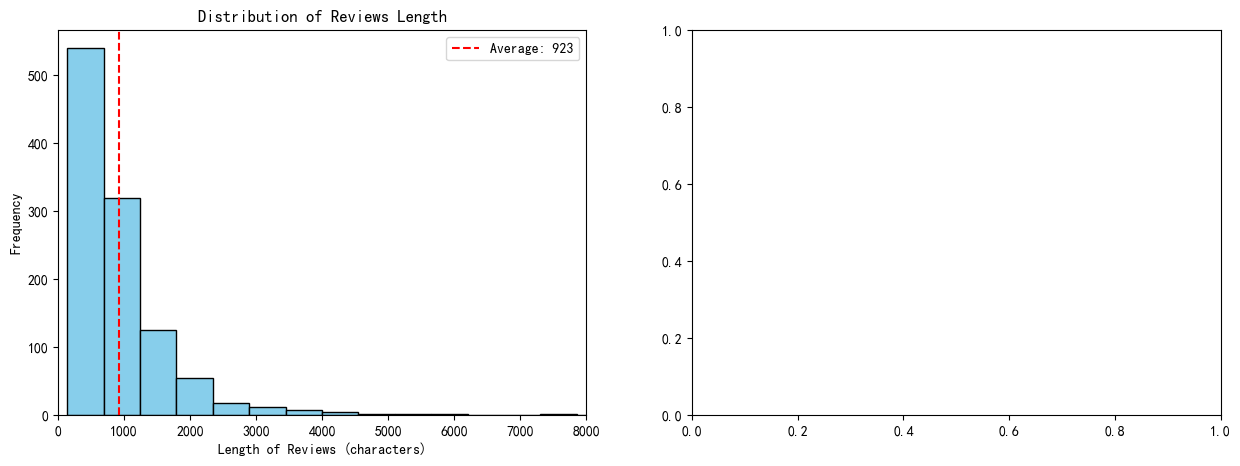

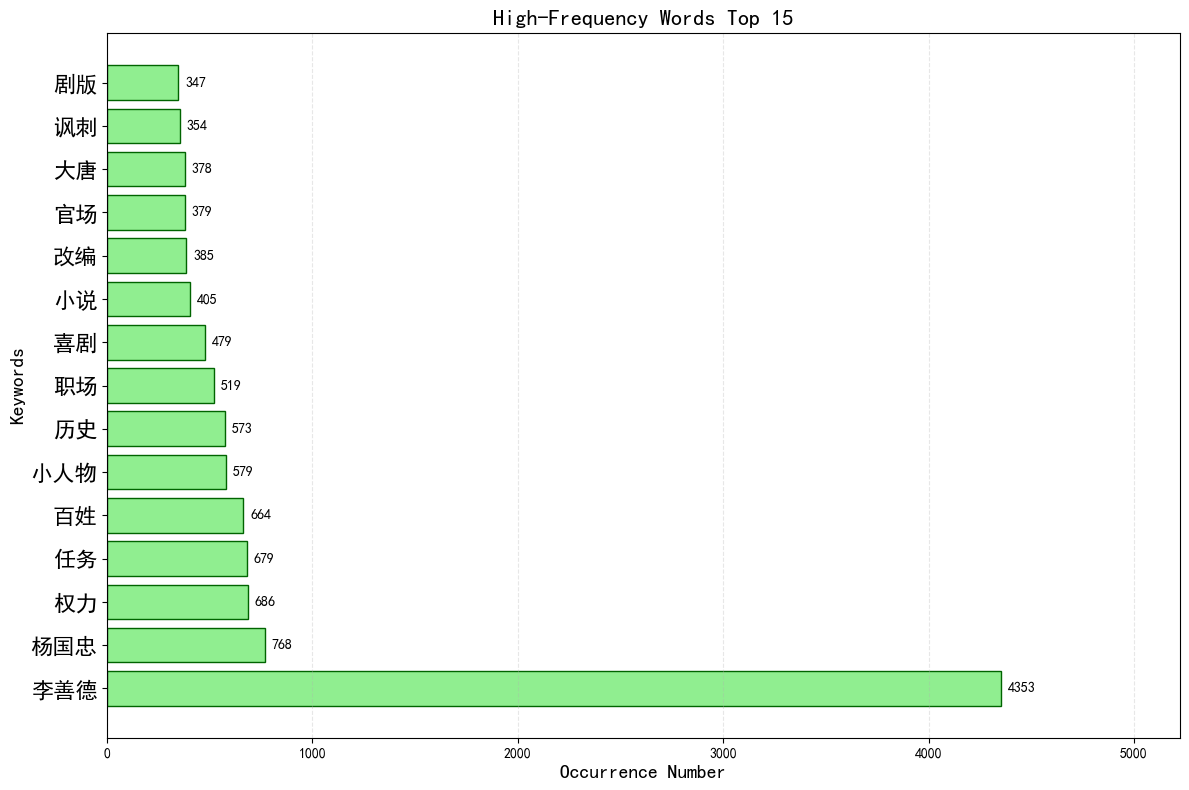

✓ 可视化图表已保存为 high_frequency_words.png


In [36]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(df['cleaned_length'], bins=30, color='skyblue', edgecolor='black')
axes[0].set_xlabel('Length of Reviews (characters)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Distribution of Reviews Length')
axes[0].axvline(df['cleaned_length'].mean(), color='red', linestyle='--', label=f'Average: {df["cleaned_length"].mean():.0f}')
axes[0].set_xlim(0, 8000)
axes[0].legend()



top_words = word_freq.most_common(15)
words, counts = zip(*top_words)


fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(words, counts, color='lightgreen', edgecolor='darkgreen')
ax.bar_label(bars, padding=5) 
ax.tick_params(axis='y', labelsize=16)

ax.set_xlabel('Occurrence Number', fontsize=14, fontweight='bold')
ax.set_ylabel('Keywords', fontsize=14, fontweight='bold')
ax.set_title('High-Frequency Words Top 15', fontsize=16, fontweight='bold')

ax.set_xlim(0, max(counts) * 1.2)

ax.grid(axis='x', alpha=0.3, linestyle='--')

plt.tight_layout()

plt.savefig('high_frequency_words_en.png', dpi=150, bbox_inches='tight')
plt.show()

print("✓ 可视化图表已保存为 high_frequency_words.png")

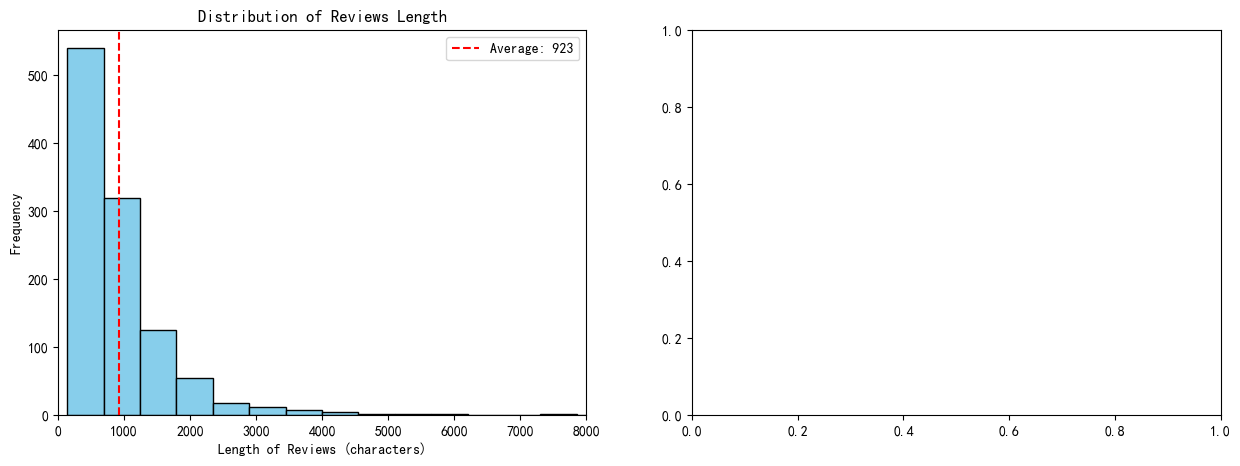

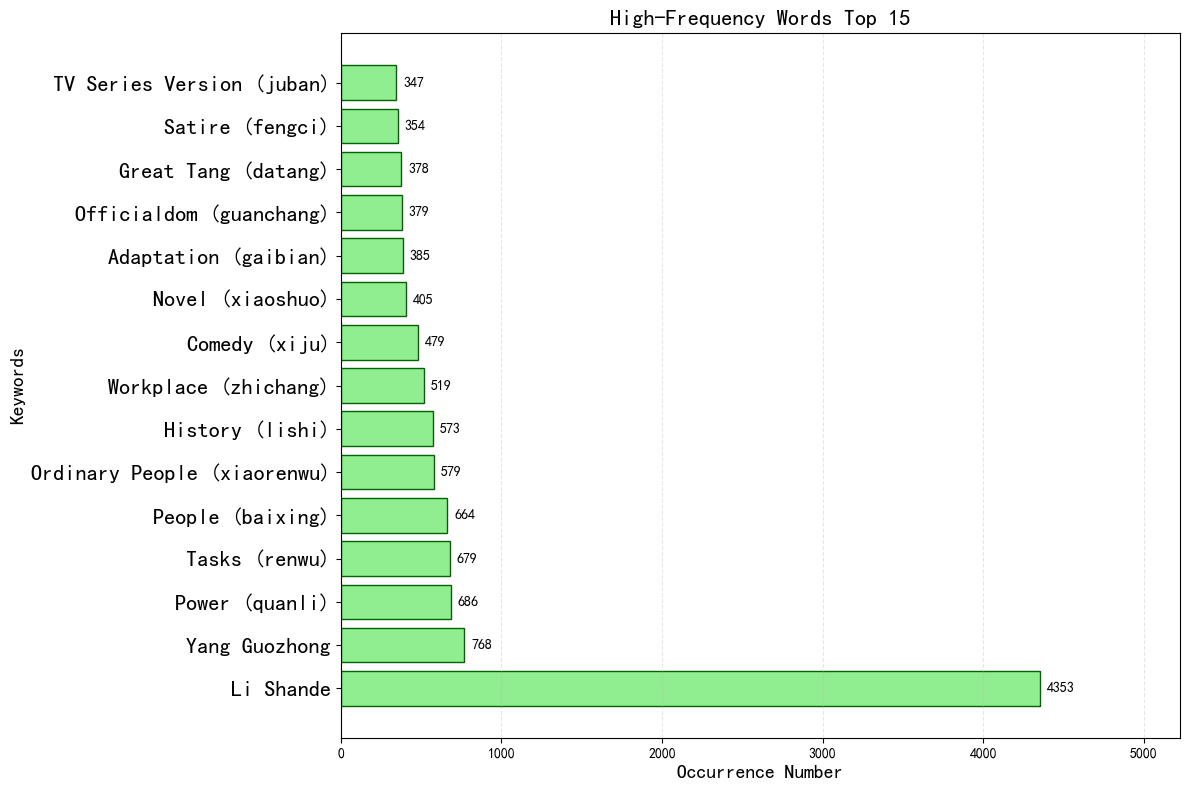

✓ 可视化图表已保存为 high_frequency_words.png


In [37]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].hist(df['cleaned_length'], bins=30, color='skyblue', edgecolor='black')
axes[0].set_xlabel('Length of Reviews (characters)')
axes[0].set_ylabel('Frequency')
axes[0].set_title('Distribution of Reviews Length')
axes[0].axvline(df['cleaned_length'].mean(), color='red', linestyle='--', label=f'Average: {df["cleaned_length"].mean():.0f}')
axes[0].set_xlim(0, 8000)
axes[0].legend()

word_translation = {
    '剧版': 'TV Series Version (juban)',
    '讽刺': 'Satire (fengci)',
    '大唐': 'Great Tang (datang)',
    '官场': 'Officialdom (guanchang)',
    '改编': 'Adaptation (gaibian)',
    '小说': 'Novel (xiaoshuo)',
    '喜剧': 'Comedy (xiju)',
    '职场': 'Workplace (zhichang)',
    '历史': 'History (lishi)',
    '小人物': 'Ordinary People (xiaorenwu)',
    '百姓': 'People (baixing)',
    '任务': 'Tasks (renwu)',
    '权力': 'Power (quanli)',
    '杨国忠': 'Yang Guozhong',
    '李善德': 'Li Shande'
}

top_words = word_freq.most_common(15)
words, counts = zip(*top_words)

english_labels = [word_translation.get(word, word) for word in words]

fig, ax = plt.subplots(figsize=(12, 8))

bars = ax.barh(english_labels, counts, color='lightgreen', edgecolor='darkgreen')
ax.bar_label(bars, padding=5) 
ax.tick_params(axis='y', labelsize=16)

ax.set_xlabel('Occurrence Number', fontsize=14, fontweight='bold')
ax.set_ylabel('Keywords', fontsize=14, fontweight='bold')
ax.set_title('High-Frequency Words Top 15', fontsize=16, fontweight='bold')

ax.set_xlim(0, max(counts) * 1.2)

ax.grid(axis='x', alpha=0.3, linestyle='--')

plt.tight_layout()

plt.savefig('high_frequency_words_en.png', dpi=150, bbox_inches='tight')
plt.show()

print("✓ 可视化图表已保存为 high_frequency_words.png")

测试 K=2 ...
  Coherence: 0.3350
测试 K=3 ...
  Coherence: 0.3800
测试 K=4 ...
  Coherence: 0.3729
测试 K=5 ...
  Coherence: 0.3593
测试 K=6 ...
  Coherence: 0.3547
测试 K=7 ...
  Coherence: 0.3447
测试 K=8 ...
  Coherence: 0.3447
测试 K=9 ...
  Coherence: 0.3446
测试 K=10 ...
  Coherence: 0.3457


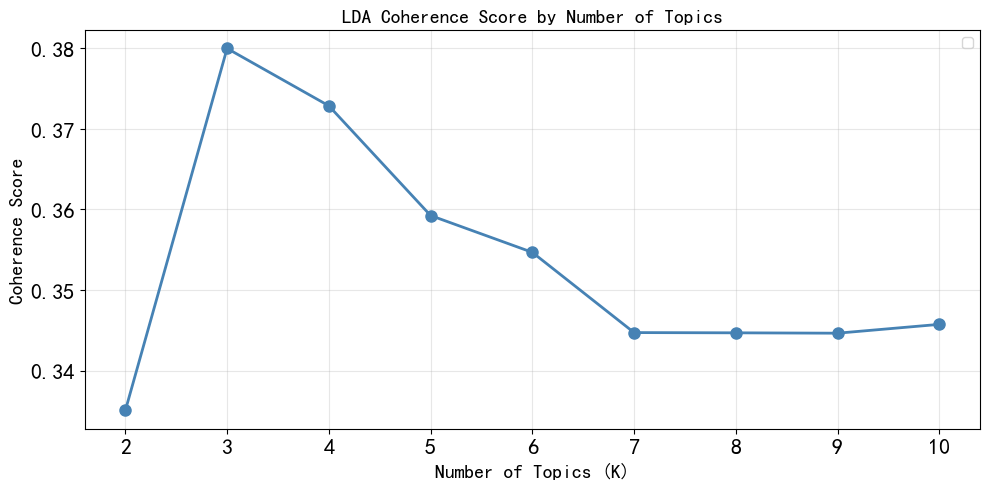


最佳主题数: K=3, Coherence=0.3800


In [17]:
import gensim
from gensim import corpora
import pyLDAvis
import pyLDAvis.gensim_models

dictionary = corpora.Dictionary(df['tokens'])
corpus = [dictionary.doc2bow(text) for text in df['tokens']]

from gensim.models import CoherenceModel
import matplotlib.pyplot as plt
import numpy as np
import warnings
warnings.filterwarnings('ignore')

plt.rcParams['font.sans-serif'] = ['SimHei', 'Arial Unicode MS', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

topic_range = range(2, 11)
coherence_scores = []

for num_topics in topic_range:
    print(f"测试 K={num_topics} ...")
    
    temp_model = gensim.models.LdaMulticore(
        corpus=corpus,
        num_topics=num_topics,
        id2word=dictionary,
        passes=30,
        iterations=300,
        alpha=0.1,
        eta=0.01,
        workers=2,
        random_state=3407
    )
    
    cm = CoherenceModel(
        model=temp_model, 
        texts=df['tokens'].tolist(), 
        dictionary=dictionary, 
        coherence='c_v'
    )
    coherence_scores.append(cm.get_coherence())
    print(f"  Coherence: {coherence_scores[-1]:.4f}")

plt.figure(figsize=(10, 5))
plt.plot(topic_range, coherence_scores, marker='o', linewidth=2, markersize=8, color='steelblue')
plt.xlabel('Number of Topics (K)', fontsize=14)
plt.ylabel('Coherence Score', fontsize=14)
plt.title('LDA Coherence Score by Number of Topics', fontsize=14)
plt.tick_params(axis='both', labelsize=16)
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('coherence_by_k.png', dpi=150)
plt.show()

print(f"\n最佳主题数: K={topic_range[np.argmax(coherence_scores)]}, Coherence={max(coherence_scores):.4f}")

测试 K=2 ...
  Perplexity: -9.7985
测试 K=3 ...
  Perplexity: -9.8513
测试 K=4 ...
  Perplexity: -9.8724
测试 K=5 ...
  Perplexity: -9.8912
测试 K=6 ...
  Perplexity: -9.9207
测试 K=7 ...
  Perplexity: -9.9447
测试 K=8 ...
  Perplexity: -9.9837
测试 K=9 ...
  Perplexity: -10.0014
测试 K=10 ...
  Perplexity: -10.0176


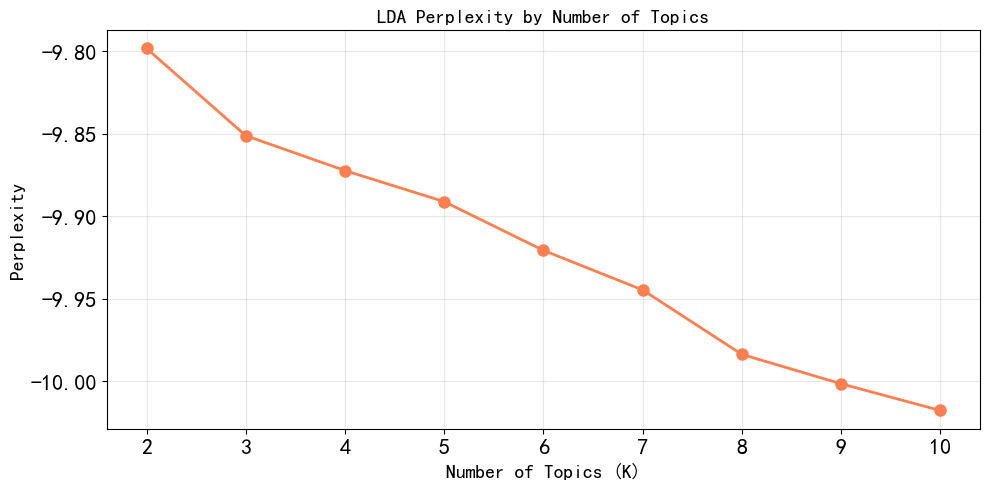


最佳 Perplexity: K=10, Perplexity=-10.0176


In [19]:
perplexity_scores = []

for num_topics in topic_range:
    print(f"测试 K={num_topics} ...")
    
    temp_model = gensim.models.LdaMulticore(
        corpus=corpus,
        num_topics=num_topics,
        id2word=dictionary,
        passes=30,
        iterations=300,
        alpha=0.1,
        eta=0.01,
        workers=2,
        random_state=42
    )
    
    perplexity = temp_model.log_perplexity(corpus)
    perplexity_scores.append(perplexity)
    print(f"  Perplexity: {perplexity:.4f}")

plt.figure(figsize=(10, 5))
plt.plot(topic_range, perplexity_scores, marker='o', linewidth=2, markersize=8, color='coral')
plt.xlabel('Number of Topics (K)', fontsize=14)
plt.ylabel('Perplexity', fontsize=14)
plt.title('LDA Perplexity by Number of Topics', fontsize=14)
plt.tick_params(axis='both', labelsize=16)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('perplexity_by_k.png', dpi=150)
plt.show()

best_k_perp = topic_range[np.argmin(perplexity_scores)]
print(f"\n最佳 Perplexity: K={best_k_perp}, Perplexity={min(perplexity_scores):.4f}")

In [20]:
lda_model = gensim.models.LdaMulticore(
    corpus,
    num_topics=3,
    id2word=dictionary,
    passes=50,
    iterations=500,
    alpha=0.1,
    eta=0.01,
    workers=2,
    random_state=42
)

print("LDA 主题结果")
for idx, topic in lda_model.print_topics(-1):
    print(f"主题 {idx+1}: {topic}")

vis = pyLDAvis.gensim_models.prepare(lda_model, corpus, dictionary)
pyLDAvis.save_html(vis, 'lda_vis.html')
print("\nLDA 可视化已保存为 lda_vis.html")

LDA 主题结果
主题 1: 0.017*"李善德" + 0.003*"杨国忠" + 0.003*"小人物" + 0.003*"喜剧" + 0.003*"职场" + 0.003*"百姓" + 0.002*"历史" + 0.002*"权力" + 0.002*"任务" + 0.002*"叙事"
主题 2: 0.011*"李善德" + 0.004*"剧版" + 0.003*"改编" + 0.003*"历史" + 0.003*"喜剧" + 0.003*"影版" + 0.002*"杨国忠" + 0.002*"电视剧" + 0.002*"大唐" + 0.002*"小说"
主题 3: 0.024*"李善德" + 0.004*"任务" + 0.004*"权力" + 0.004*"杨国忠" + 0.004*"百姓" + 0.002*"小人物" + 0.002*"历史" + 0.002*"职场" + 0.002*"盛唐" + 0.002*"官场"

LDA 可视化已保存为 lda_vis.html


In [38]:
labor_terms = ['内卷', '剥削', '压榨', '底层', '打工人', '996', '007', 'KPI', '职场', '加班', '小人物']
critique_terms = ['资本主义', '资本', '资本家', '权力', '官僚', '腐败', '讽刺', '影射']
history_terms = ['唐朝', '历史', '借古讽今', '大唐', '古装']

df['has_labor'] = df['cleaned_content'].apply(lambda x: any(term in x for term in labor_terms))
df['has_critique'] = df['cleaned_content'].apply(lambda x: any(term in x for term in critique_terms))
df['has_history'] = df['cleaned_content'].apply(lambda x: any(term in x for term in history_terms))

df['has_labor_or_critique'] = df['has_labor'] | df['has_critique']

print(f"The proportion of comments containing labor metaphors: {df['has_labor'].mean():.2%}")
print(f"The proportion of comments containing critical contents: {df['has_critique'].mean():.2%}")
print(f"The proportion of comments involving historical references or discussions that use history as a metaphor for the present: {df['has_history'].mean():.2%}")
print(f"包含劳动或批判的评论占比: {df['has_labor_or_critique'].mean():.2%} ({df['has_labor_or_critique'].sum()}条)")

cross_ratio = df[(df['has_labor']) & (df['has_history'])].shape[0] / df.shape[0]
print(f"Discuss the proportion of comments that use labor metaphors and historical analogies to the present: {cross_ratio:.2%}")

The proportion of comments containing labor metaphors: 59.76%
The proportion of comments containing critical contents: 49.26%
The proportion of comments involving historical references or discussions that use history as a metaphor for the present: 47.61%
包含劳动或批判的评论占比: 73.76% (801条)
Discuss the proportion of comments that use labor metaphors and historical analogies to the present: 32.32%


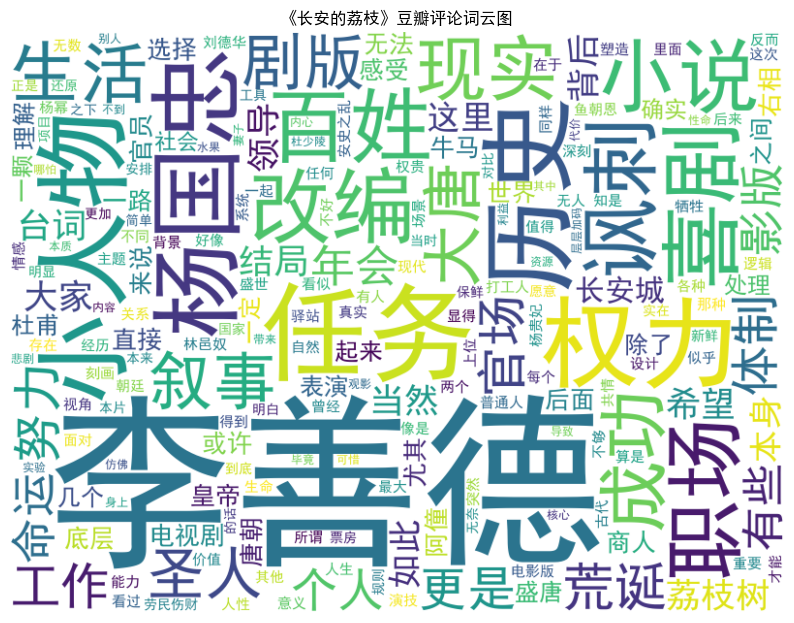

In [39]:
from wordcloud import WordCloud
import matplotlib.pyplot as plt

all_words_str = ' '.join([word for tokens in df['tokens'] for word in tokens])
wordcloud = WordCloud(font_path="simhei.ttf", background_color='white', width=800, height=600).generate(all_words_str)

plt.figure(figsize=(10, 8))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis('off')
plt.title('《长安的荔枝》豆瓣评论词云图')
plt.savefig('wordcloud.png', dpi=150, bbox_inches='tight')
plt.show()